<div align="center" style="text-align: center; padding: 50px 0; border-top: 4px solid #1f4e79; border-bottom: 4px solid #1f4e79;">

<h1 style="text-align: center; color: #1f4e79; margin-bottom: 8px;">Forecasting US Electricity and Gas Output</h1>

<h3 style="text-align: center; color: #555; font-weight: normal;">Time Series Analysis: ETS + ARIMA vs Facebook Prophet</h3>

<br>

<p style="text-align: center; font-size: 16px;"><b>Author:</b> Tanguy Mandrillon &nbsp;|&nbsp; <b>Year:</b> 2026</p>

</div>


> **Note on AI usage:** AI (Claude Code) was used as an assistant to write the code of this notebook, to draft the text and to design the layout (title page, table of contents and plot style). The analysis was led by me. Details and prompts are in section 4.

# Introduction

In this notebook, we analyze a time series and forecast it with two different methods.

In the first approach, we apply an ETS decomposition to split the series into its trend, seasonal and residual components. The trend and seasonality are extrapolated, while the residual $R_t$ is modeled with an ARIMA model. We then recombine the three components to obtain the final forecast and compare it with the test set.

The second approach uses Facebook Prophet, a more automated method, to produce the same forecast.

Finally, we compare both approaches using error metrics and draw conclusions.


## Table of contents

| Part | Content |
|---|---|
| **0. Dataset** | Import, plot and train-test split |
| **1. ETS Decomposition + ARIMA** | Model choice, trend, seasonality, residual forecasting, recomposition and errors |
| **2. Facebook Prophet** | Forecasting, errors and parameter tuning |
| **3. Conclusion** | Comparison of both approaches |
| **4. AI-usage policy** | Where AI was used, planning session and prompts |

---


In [1]:
import matplotlib.pyplot as plt

# Global plot style shared by all the figures of the notebook
plt.rcParams.update({
    "figure.dpi": 110,
    "figure.facecolor": "white",
    "axes.facecolor": "#fafafa",
    "axes.grid": True,
    "grid.color": "#dddddd",
    "grid.linestyle": "-",
    "grid.linewidth": 0.6,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#444444",
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.titlepad": 12,
    "axes.labelsize": 11,
    "axes.labelcolor": "#333333",
    "legend.frameon": True,
    "legend.framealpha": 0.9,
    "legend.edgecolor": "#cccccc",
    "legend.fontsize": 9,
    "lines.linewidth": 1.2,
    "font.size": 10,
})


# 0. Dataset
First of all, we need to find a suitable time series (TS). For the analysis to make sense, the TS should have three distinct components: trend, seasonality and residual.

Energy production is a natural candidate: it grows with the economy and the population (trend), and it follows the weather (seasonality), with heating in winter and air conditioning in summer.

We use the [IPG2211A2N](https://fred.stlouisfed.org/series/IPG2211A2N) series from FRED (Federal Reserve Bank of St. Louis): the industrial production index of US electric and gas utilities, monthly, with 2017 = 100, **not seasonally adjusted**. The source is the Industrial Production release (G.17) of the Federal Reserve Board. The seasonally adjusted version must not be used, otherwise the seasonal component we want to study would already be removed.

## 0.1. Import dataset
Let's start by loading the dataset into a pandas DataFrame.

The file `IPG2211A2N.csv` has two columns: `observation_date` (first day of the month) and `IPG2211A2N` (the index). It covers January 1939 to August 2026. We keep **January 1995 onwards** (380 months): 30 years are enough to estimate a stable seasonal profile, and the older decades (much faster growth, oil shocks) say little about today's energy sector. We rename the column to `output`, check that there is no missing value, and set an explicit monthly frequency (`MS`, month start) on the index, which statsmodels needs.

In [2]:
import pandas as pd

raw = pd.read_csv("IPG2211A2N.csv", parse_dates=["observation_date"], index_col="observation_date")

# Monthly output of US electric and gas utilities, index 2017 = 100 (not seasonally adjusted)
df = raw.rename(columns={"IPG2211A2N": "output"})
df.index.name = "date"
# Analysis window: January 1995 onwards
df = df.loc["1995-01-01":]
print(f"Missing values: {df['output'].isna().sum()}")
# Explicit monthly frequency (month start), needed by statsmodels
df = df.asfreq("MS")

df

Missing values: 0


,output
date,
1995-01-01,91.3554
1995-02-01,86.3571
1995-03-01,80.3024
1995-04-01,72.9393
1995-05-01,72.4021
...,...
2026-04-01,94.5652
2026-05-01,97.7156
2026-06-01,110.7733


## 0.2. Plot TS

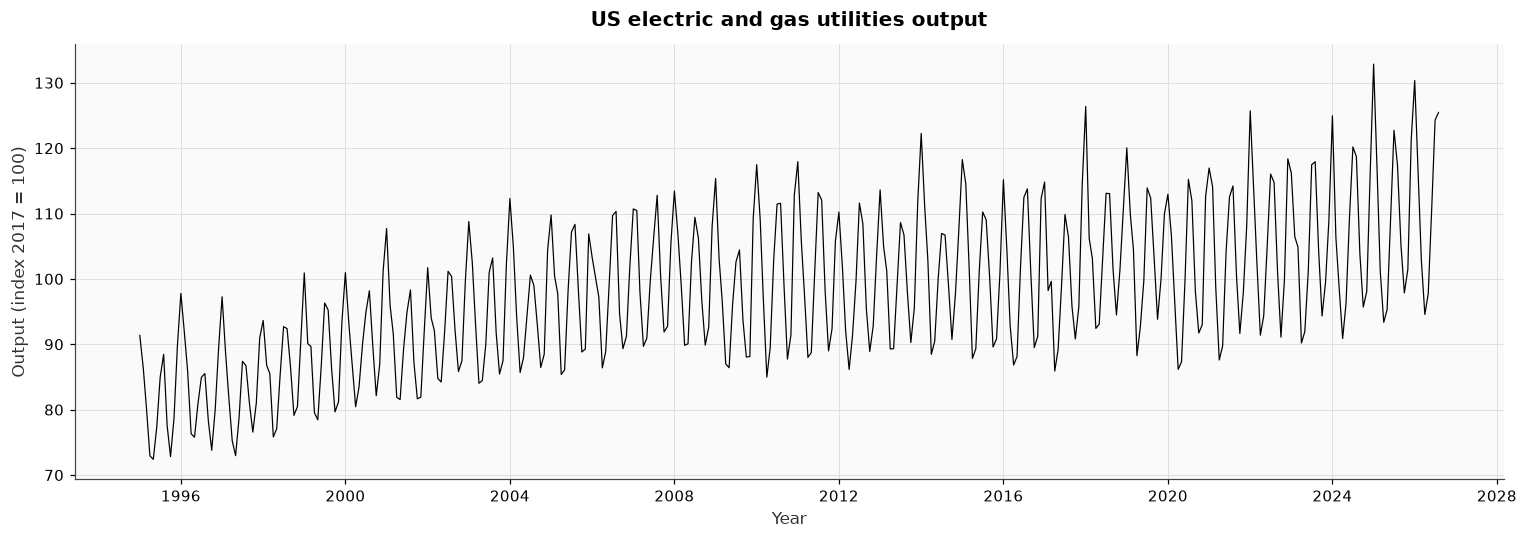

In [3]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(df.index, df.output, color="black", linewidth=0.8)
ax.set_title("US electric and gas utilities output")
ax.set_xlabel("Year")
ax.set_ylabel("Output (index 2017 = 100)")
plt.tight_layout()
plt.show()

> Seasonality?

The series shows a very regular yearly pattern with **two peaks**: a high one in winter (January, heating) and a second one in July-August (air conditioning). The lows are in spring (April-May) and in autumn (October), when there is little need for heating or cooling. The seasonal swings get bigger as the series grows: about 25 points between the highest and the lowest month in the late 1990s, about 35 points in recent years.

> Trend?

The yearly average grows from about 81 in 1995 to about 107 in 2024, but not at a constant speed: fast growth until the mid-2000s, an almost flat level from about 2007 to 2016, then growth again. Unlike retail or transport series, there is no big shock: in 2020 the yearly average only dipped from 104.0 to 101.0. The month-to-month noise mostly comes from the weather (a cold winter or a hot summer).

## 0.3. train-test split
To compute the errors between our forecast and reality, we have to keep a part of the data to test our result. We keep the year 2025 plus the first eight months of 2026 as test set. The train set contains only complete years, which is convenient for the yearly windows used later.

Train-set: January 1995 -> December 2024 (360 months, 30 years)

Test-set: January 2025 -> August 2026 (20 months)

In [4]:
df_train = df.loc[:"2024-12-01"]
df_test = df.loc["2025-01-01":]

print(f"Train: {df_train.index.min():%Y-%m} -> {df_train.index.max():%Y-%m} ({len(df_train)} months)")
print(f"Test:  {df_test.index.min():%Y-%m} -> {df_test.index.max():%Y-%m} ({len(df_test)} months)")

Train: 1995-01 -> 2024-12 (360 months)
Test:  2025-01 -> 2026-08 (20 months)


# 1. ETS Decomposition + ARIMA
We will perform the ETS Decomposition. Our decomposition/recomposition will follow the next steps:
1. Determine the model (additive or multiplicative)
1. Determine if there is a trend component (Anova test)
1. Estimate the trend using CMA (Center Moving Average)
1. Detrend
1. Determine if there is a seasonal component (Anova test)
1. Forecast St and ensure area conservation is met
1. Remove seasonality, $Y_t' = R_t \cdot T_t$
1. Compute and forecast the trend (method varies depending on linearity)
1. Remove trend, $Y_t'' = R_t$
1. Forecast R_t using ARIMA model
1. Recomposition
1. Error's measurement


## 1.1. Additive or Multiplicative

In [5]:
import statsmodels.api as sm

# One window per calendar year = one full seasonal cycle (12 months), on the train set only
windows = df_train["output"].groupby(df_train.index.year).agg(mean="mean", std="std", n="size")
windows = windows[windows["n"] == 12]

# Fit Std = a * mean + b + e
X = sm.add_constant(windows["mean"])
ols = sm.OLS(windows["std"], X).fit()
print(ols.summary().tables[1])

# t-test on H0: a = 0 at the 5% level
alpha = 0.05
a_hat = ols.params["mean"]
t_stat = ols.tvalues["mean"]
p_value = ols.pvalues["mean"]
print(f"\na = {a_hat:.4f}, t = {t_stat:.3f}, p-value = {p_value:.2e}")
if p_value < alpha:
    print("H0 rejected: the std grows with the level -> multiplicative model")
else:
    print("H0 not rejected: the std does not depend on the level -> additive model")

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         -7.8641      2.066     -3.806      0.001     -12.096      -3.632
mean           0.1730      0.021      8.158      0.000       0.130       0.216

a = 0.1730, t = 8.158, p-value = 7.01e-09
H0 rejected: the std grows with the level -> multiplicative model


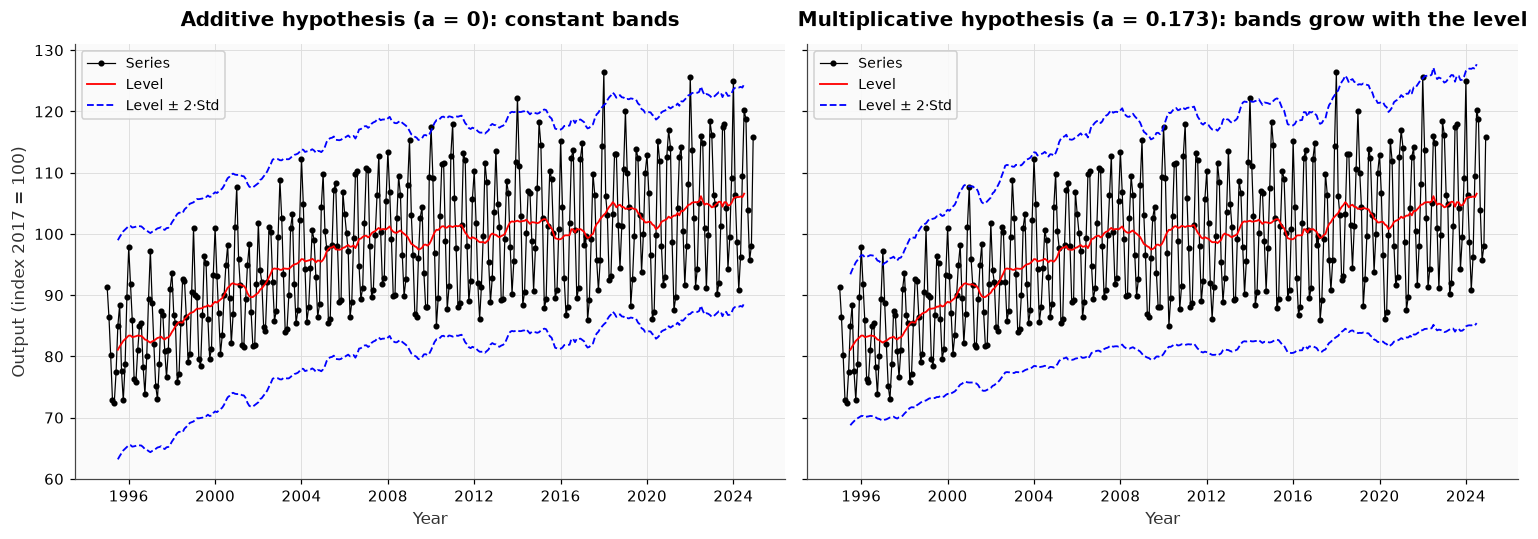

In [6]:
k = 2  # band half-width, in number of standard deviations

# Level: 12-month centered moving average
level = df_train["output"].rolling(12, center=True).mean()

# Additive hypothesis (a = 0): constant spread, equal to the average yearly std
std_add = windows["std"].mean()
# Multiplicative hypothesis: spread proportional to the level, from the fit Std = a * mean + b
std_mult = ols.params["mean"] * level + ols.params["const"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
bands = [
    (axes[0], std_add, "Additive hypothesis (a = 0): constant bands"),
    (axes[1], std_mult, f"Multiplicative hypothesis (a = {a_hat:.3f}): bands grow with the level"),
]
for ax, spread, title in bands:
    ax.plot(df_train.index, df_train["output"], color="black", marker=".", linewidth=0.8, label="Series")
    ax.plot(level.index, level, color="red", label="Level")
    ax.plot(level.index, level + k * spread, color="blue", linestyle="--", label=f"Level ± {k}·Std")
    ax.plot(level.index, level - k * spread, color="blue", linestyle="--")
    ax.set_title(title)
    ax.set_xlabel("Year")
    ax.legend(loc="upper left")
axes[0].set_ylabel("Output (index 2017 = 100)")
plt.tight_layout()
plt.show()

> Additive or multiplicative ?

The t-test rejects $a = 0$ ($a = 0.173$, $t = 8.16$, p-value $= 7 \times 10^{-9}$). The yearly standard deviation grows with the yearly mean: when the output is higher, the gap between the winter peak and the spring low grows with it. Graphically, the bands of the multiplicative hypothesis (right) are narrow in the 1990s and wide in the 2020s, like the series, while the constant bands (left) are clearly too wide in the 1990s.

TS's model: $Y_t = T_t \cdot S_t \cdot R_t$

In practical terms, the seasonal effect is a **percentage** of the activity ("January is 15% above an average month"), not a fixed number of index points.

## 1.2. Trend Component

### 1.2.1. Is there a trend ?
We'll perform an Anova test on the Buys-Ballot table (output by year and by month) to determine if there is a trend or not.

month,1,2,3,4,5,6,7,8,9,10,11,12,Average
year,,,,,,,,,,,,,
1995,91.4,86.4,80.3,72.9,72.4,77.4,85.0,88.5,77.6,72.8,78.7,89.7,81.1
1996,97.8,91.8,85.9,76.3,75.8,81.0,84.9,85.5,78.3,73.8,80.1,89.4,83.4
1997,97.3,88.7,82.0,75.2,73.0,78.8,87.4,86.7,81.0,76.6,81.1,91.0,83.2
1998,93.6,86.8,85.5,75.8,77.1,85.4,92.7,92.4,86.5,79.1,80.5,90.6,85.5
1999,100.9,90.1,89.7,79.5,78.4,86.8,96.3,95.3,86.2,79.7,81.2,93.4,88.1
2000,101.0,93.1,87.0,80.4,83.5,90.0,94.9,98.2,89.6,82.1,86.9,101.2,90.7
2001,107.7,95.9,91.7,81.9,81.5,89.3,94.9,98.3,87.2,81.7,81.9,91.9,90.3
2002,101.7,94.0,92.1,84.8,84.2,92.1,101.2,100.4,92.2,85.8,87.5,99.5,93.0
2003,108.8,102.5,93.4,84.0,84.5,90.0,101.0,103.2,91.8,85.5,87.5,102.3,94.5


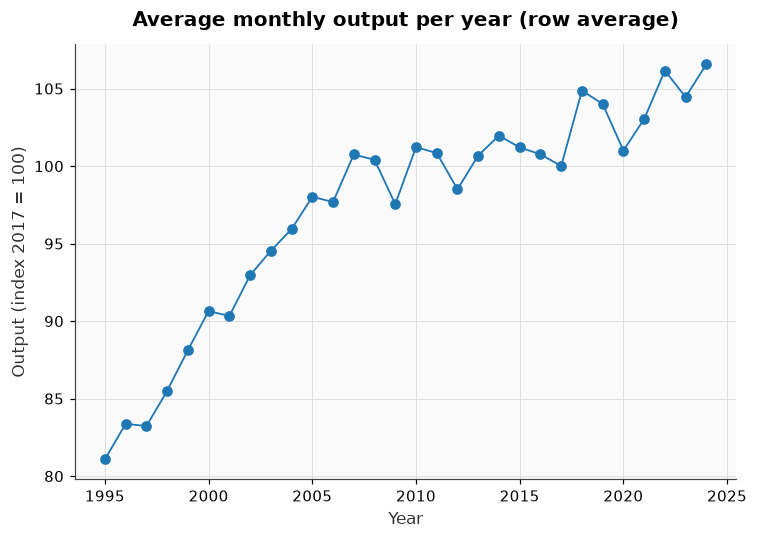

In [7]:
# Buys-Ballot table on the train set: years as rows, months as columns
long = pd.DataFrame(
    {"output": df_train["output"], "year": df_train.index.year, "month": df_train.index.month}
)
table = long.pivot(index="year", columns="month", values="output")

year_mean = table.mean(axis=1)  # average by row
month_mean = table.mean(axis=0)  # average by column

# Display the table with the averages as margins
display_table = table.copy()
display_table["Average"] = year_mean
display_table.loc["Average"] = pd.concat([month_mean, pd.Series({"Average": table.stack().mean()})])
display(display_table.round(1))

fig, axes = plt.subplots(1, 1, figsize=(7, 5))
axes.plot(year_mean.index, year_mean, marker="o")
axes.set_title("Average monthly output per year (row average)")
axes.set_xlabel("Year")
axes.set_ylabel("Output (index 2017 = 100)")
plt.tight_layout()
plt.show()

In [8]:
import statsmodels.formula.api as smf

# Two-way Anova on the Buys-Ballot table (year + month factors, no interaction).
# The month factor absorbs the seasonality, so the year factor tests
# H0: all yearly means are equal (no trend) against H1: at least one differs.
anova_fit = smf.ols("output ~ C(year) + C(month)", data=long).fit()
anova = sm.stats.anova_lm(anova_fit)
print(anova)

f_year = anova.loc["C(year)", "F"]
p_year = anova.loc["C(year)", "PR(>F)"]
print(f"\nYear factor: F = {f_year:.2f}, p-value = {p_year:.2e}")
if p_year < alpha:
    print("H0 rejected: the yearly means differ -> there is a trend")
else:
    print("H0 not rejected: the yearly means are equal -> no trend")

             df        sum_sq      mean_sq           F         PR(>F)
C(year)    29.0  17799.149815   613.763787   74.553489  5.515322e-124
C(month)   11.0  24477.794802  2225.254073  270.300167  2.200240e-154
Residual  319.0   2626.176876     8.232529         NaN            NaN

Year factor: F = 74.55, p-value = 5.52e-124
H0 rejected: the yearly means differ -> there is a trend


> Is there a trend ?

The row averages grow from about 81 in 1995 to about 107 in 2024, and the plot shows the flat period between about 2007 and 2016. The column averages show the seasonal profile: January (111.3) and July-August (105.6) are the highest months, April (85.3) and May (86.7) the lowest.

The two-way Anova rejects H0 for the year factor ($F = 74.6$, p-value far below 5%): the yearly means are not all equal, so **there is a trend component** in the series. Note that the month factor is even more significant ($F = 270$), which announces the seasonality.

### 1.2.2. Estimate the trend
To do so, we'll compute a CMA(12) to obtain a smooth trend. We choose 12 because it is the number of components in a year (12 months).


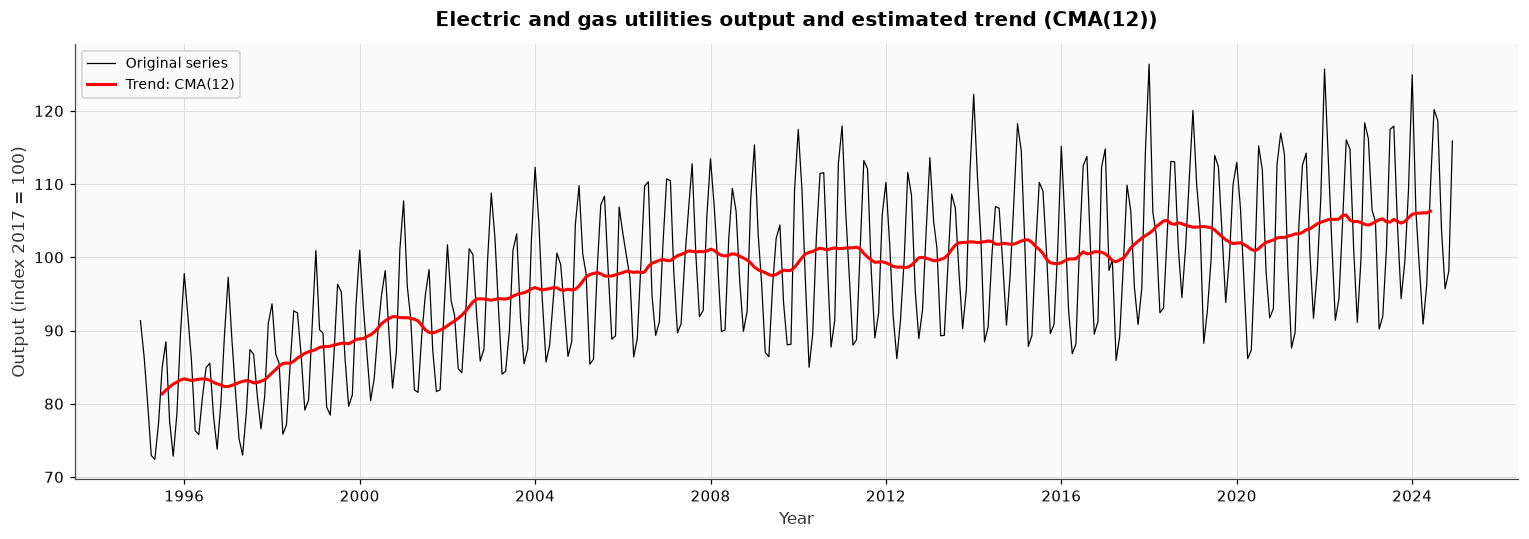

In [9]:
# CMA(12): the order is even, so a plain 12-month window is not centered on a month.
# We use a 2x12 moving average, i.e. weights [1/24, 1/12, ..., 1/12, 1/24] over 13 months,
# which is centered on month t and covers exactly one year.
# The first and last 6 months have no CMA value.
cma = df_train["output"].rolling(12).mean().rolling(2).mean().shift(-6)
df_train = df_train.assign(cma=cma)

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(df_train.index, df_train["output"], color="black", linewidth=0.8, label="Original series")
ax.plot(df_train.index, df_train["cma"], color="red", linewidth=2, label="Trend: CMA(12)")
ax.set_title("Electric and gas utilities output and estimated trend (CMA(12))")
ax.set_xlabel("Year")
ax.set_ylabel("Output (index 2017 = 100)")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

> Trend

The red line is our estimated trend. It has been obtained with a CMA(12) on the original Time Series. Doing that, we lose the 6 first points and the 6 last points. This is not a problem because we still have 348 points to compute our average by season.

The CMA shows three phases: a steady growth until about 2007, a plateau until about 2016, and a slower growth afterwards. It also moves a little with unusual winters or summers, because a 12-month average is pulled up or down for a whole year by one extreme month. A straight line will therefore not be enough to describe this trend (see section 1.4).

### 1.2.3. Detrend
We will remove the trend to our original Time Series to be able to decompose the seasonal component. If the model is multiplicative we divide the original TS by the estimated trend, otherwise we subtract it (see section 1.1 for the choice of the model).


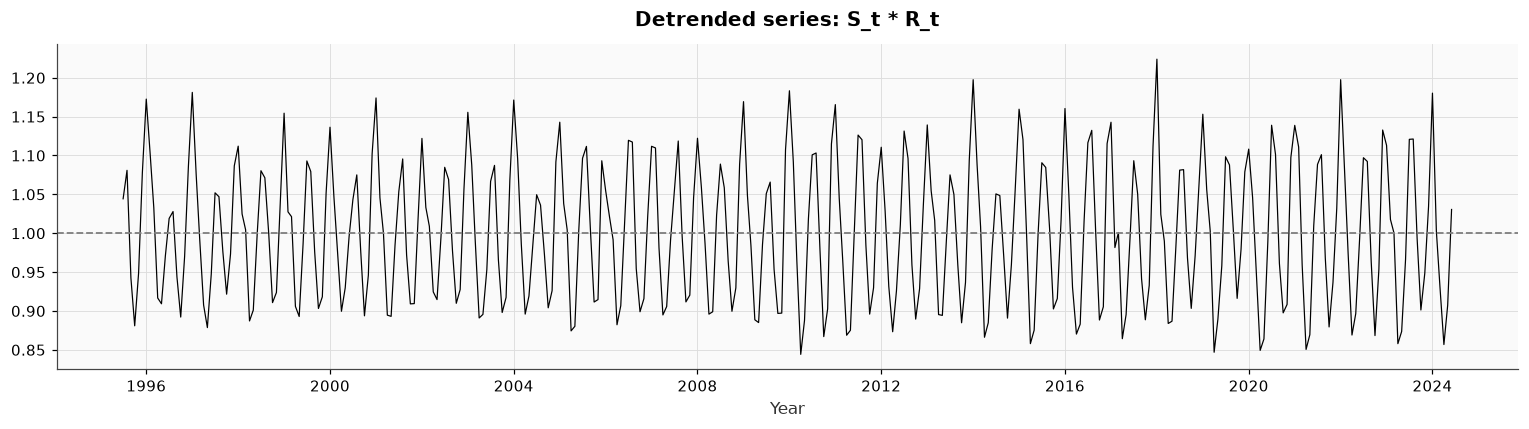

In [10]:
# Multiplicative model: Y_t / T_t = S_t * R_t
# The CMA is NaN for the first and last 6 months, so the ratio is NaN there too
df_train = df_train.assign(seasonal_residual=df_train["output"] / df_train["cma"])

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(df_train.index, df_train.seasonal_residual, color="black", linewidth=0.8)
ax.axhline(1, color="grey", linestyle="--")
ax.set_title("Detrended series: S_t * R_t")
ax.set_xlabel("Year")
plt.tight_layout()
plt.show()

## 1.3. Seasonal Component

### 1.3.1. Is there a seasonal component ?
We'll perform an Anova test on the average of the detrended series per month to determine if there is a seasonal component or not.


month,1,2,3,4,5,6,7,8,9,10,11,12,Average
year,,,,,,,,,,,,,
1995,NaN,NaN,NaN,NaN,NaN,NaN,1.044,1.081,0.942,0.881,0.949,1.078,0.996
1996,1.173,1.102,1.033,0.917,0.909,0.971,1.019,1.028,0.944,0.892,0.970,1.086,1.004
1997,1.181,1.075,0.992,0.908,0.879,0.948,1.052,1.047,0.976,0.922,0.973,1.087,1.003
1998,1.112,1.025,1.004,0.887,0.901,0.999,1.080,1.071,0.999,0.911,0.924,1.039,0.996
1999,1.154,1.028,1.021,0.906,0.893,0.986,1.093,1.079,0.976,0.903,0.918,1.052,1.001
2000,1.136,1.047,0.976,0.900,0.930,0.996,1.043,1.075,0.978,0.894,0.946,1.102,1.002
2001,1.174,1.046,1.000,0.895,0.893,0.985,1.053,1.096,0.972,0.909,0.909,1.018,0.996
2002,1.122,1.033,1.009,0.925,0.915,0.994,1.085,1.069,0.977,0.910,0.928,1.056,1.002
2003,1.156,1.088,0.990,0.891,0.896,0.953,1.067,1.087,0.966,0.898,0.917,1.069,0.998


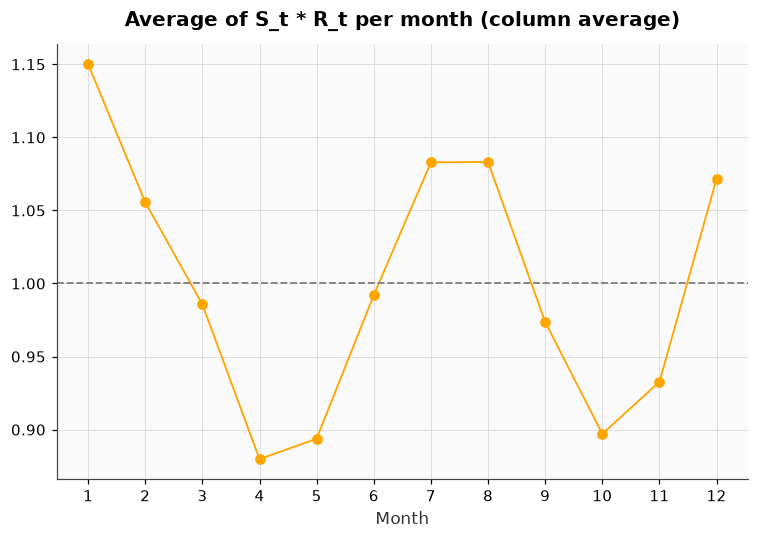

In [11]:
# Buys-Ballot table of the detrended series (S_t * R_t): years as rows, months as columns
# The first 6 and last 6 months are NaN (no CMA value), so they are dropped
detrended = df_train["seasonal_residual"].dropna()
long_s = pd.DataFrame(
    {"seasonal_residual": detrended, "year": detrended.index.year, "month": detrended.index.month}
)
table_s = long_s.pivot(index="year", columns="month", values="seasonal_residual")

year_mean_s = table_s.mean(axis=1)  # average by row
month_mean_s = table_s.mean(axis=0)  # average by column

# Display the table with the averages as margins
display_table_s = table_s.copy()
display_table_s["Average"] = year_mean_s
display_table_s.loc["Average"] = pd.concat([month_mean_s, pd.Series({"Average": table_s.stack().mean()})])
display(display_table_s.round(3))

fig, axes = plt.subplots(1, 1, figsize=(7, 5))
axes.plot(month_mean_s.index, month_mean_s, marker="o", color="orange")
axes.axhline(1, color="grey", linestyle="--")
axes.set_title("Average of S_t * R_t per month (column average)")
axes.set_xlabel("Month")
axes.set_xticks(range(1, 13))
plt.tight_layout()
plt.show()

In [12]:
# One-way Anova with the month as factor, on the detrended series.
# H0: all monthly means are equal (no seasonality) against H1: at least one differs.
anova_s_fit = smf.ols("seasonal_residual ~ C(month)", data=long_s).fit()
anova_s = sm.stats.anova_lm(anova_s_fit)
print(anova_s)

f_month = anova_s.loc["C(month)", "F"]
p_month = anova_s.loc["C(month)", "PR(>F)"]
print(f"\nMonth factor: F = {f_month:.2f}, p-value = {p_month:.2e}")
if p_month < alpha:
    print("H0 rejected: the monthly means differ -> there is a seasonal component")
else:
    print("H0 not rejected: the monthly means are equal -> no seasonal component")

             df    sum_sq   mean_sq           F         PR(>F)
C(month)   11.0  2.504680  0.227698  338.574942  2.216885e-174
Residual  336.0  0.225966  0.000673         NaN            NaN

Month factor: F = 338.57, p-value = 2.22e-174
H0 rejected: the monthly means differ -> there is a seasonal component


> Is there a seasonal component ?

The column averages show a clear seasonal profile with two peaks. January is far above the trend (1.150), followed by July and August (1.083 each), December (1.072) and February (1.056). The lowest months are April (0.880), May (0.894) and October (0.897).

The Anova test rejects H0 ($F = 339$, p-value far below 5%): the monthly means are not all equal, so **there is a seasonal component** in the series.

The average of the averages is 0.99986, very close to 1 but not exactly. We therefore implement the area conservation explicitly in the next section.

### 1.3.2. Forecast and area conservation
We almost forecast our seasonal component, but we need to ensure the area conservation is met: the 12 seasonal coefficients must average exactly 1 (multiplicative model).


In [13]:
# Area conservation: divide each monthly average by the average of averages,
# so that the 12 seasonal coefficients average exactly 1 (sum = 12)
average_of_average = month_mean_s.mean()
seasonal_coef = month_mean_s / average_of_average

# New row in the matrix with the seasonal coefficients
display_table_s.loc["Seasonal coefficient"] = pd.concat(
    [seasonal_coef, pd.Series({"Average": seasonal_coef.mean()})]
)
display(display_table_s.round(3))

print(f"Average of averages before correction: {average_of_average:.6f}")
print(f"Sum of the seasonal coefficients: {seasonal_coef.sum():.6f}")

# Seasonal component S_t: each month gets the coefficient of its calendar month.
# Unlike the CMA, it is defined for every month, including the first and last 6.
df_train = df_train.assign(seasonal=df_train.index.month.map(seasonal_coef).to_numpy())

df_train

month,1,2,3,4,5,6,7,8,9,10,11,12,Average
year,,,,,,,,,,,,,
1995,NaN,NaN,NaN,NaN,NaN,NaN,1.044,1.081,0.942,0.881,0.949,1.078,0.996
1996,1.173,1.102,1.033,0.917,0.909,0.971,1.019,1.028,0.944,0.892,0.970,1.086,1.004
1997,1.181,1.075,0.992,0.908,0.879,0.948,1.052,1.047,0.976,0.922,0.973,1.087,1.003
1998,1.112,1.025,1.004,0.887,0.901,0.999,1.080,1.071,0.999,0.911,0.924,1.039,0.996
1999,1.154,1.028,1.021,0.906,0.893,0.986,1.093,1.079,0.976,0.903,0.918,1.052,1.001
2000,1.136,1.047,0.976,0.900,0.930,0.996,1.043,1.075,0.978,0.894,0.946,1.102,1.002
2001,1.174,1.046,1.000,0.895,0.893,0.985,1.053,1.096,0.972,0.909,0.909,1.018,0.996
2002,1.122,1.033,1.009,0.925,0.915,0.994,1.085,1.069,0.977,0.910,0.928,1.056,1.002
2003,1.156,1.088,0.990,0.891,0.896,0.953,1.067,1.087,0.966,0.898,0.917,1.069,0.998


Average of averages before correction: 0.999860
Sum of the seasonal coefficients: 12.000000


,output,cma,seasonal_residual,seasonal
date,,,,
1995-01-01,91.3554,NaN,NaN,1.150264
1995-02-01,86.3571,NaN,NaN,1.055780
1995-03-01,80.3024,NaN,NaN,0.985816
1995-04-01,72.9393,NaN,NaN,0.879923
1995-05-01,72.4021,NaN,NaN,0.893925
...,...,...,...,...
2024-08-01,118.7029,NaN,NaN,1.083330
2024-09-01,103.8493,NaN,NaN,0.973766
2024-10-01,95.6967,NaN,NaN,0.897230


> Seasonal component

Each calendar month now has its coefficient $S_m$, and the 12 coefficients sum to exactly 12. The seasonal component has no NaN, because it repeats itself every year.

Practical reading: in January the output is on average **15% above** a typical month (heating), in July and August 8% above (air conditioning), and in April, May and October 10 to 12% below. The rows of the table are stable over 30 years, so fixed coefficients are a reasonable choice. The differences between years come from the weather: January goes from 1.054 in 2006 (a mild winter) to 1.224 in 2018 (a cold one). These weather effects cannot be predicted from the calendar, so they will end up in the residual $R_t$.

### 1.3.3. Remove Seasonality
We are now able to compute a TS with the trend and the residual component. Based on this we'll forecast the trend.


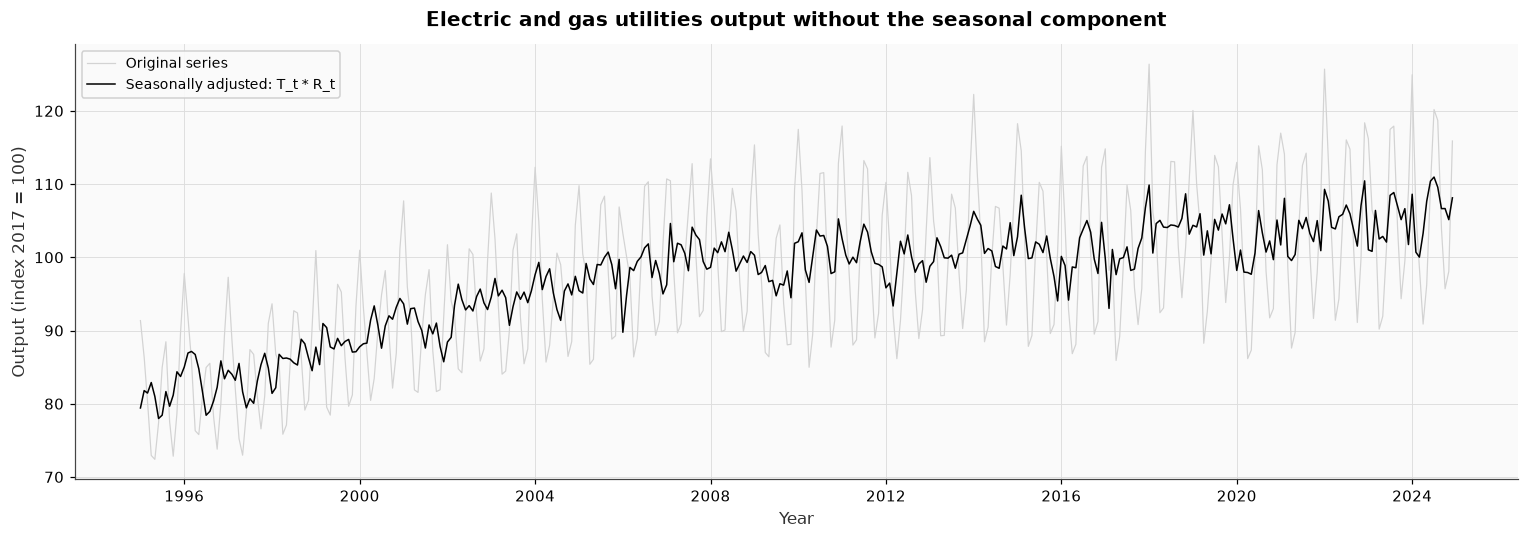

,output,cma,seasonal_residual,seasonal,trend_residual
date,,,,,
1995-01-01,91.3554,NaN,NaN,1.150264,79.421213
1995-02-01,86.3571,NaN,NaN,1.055780,81.794607
1995-03-01,80.3024,NaN,NaN,0.985816,81.457807
1995-04-01,72.9393,NaN,NaN,0.879923,82.892829
1995-05-01,72.4021,NaN,NaN,0.893925,80.993445
...,...,...,...,...,...
2024-08-01,118.7029,NaN,NaN,1.083330,109.572287
2024-09-01,103.8493,NaN,NaN,0.973766,106.647101
2024-10-01,95.6967,NaN,NaN,0.897230,106.657878


In [14]:
# Multiplicative model: Y_t / S_t = T_t * R_t
# The seasonal component is defined for every month, so there is no NaN here
df_train = df_train.assign(trend_residual=df_train["output"] / df_train["seasonal"])

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(df_train.index, df_train["output"], color="lightgrey", linewidth=0.8, label="Original series")
ax.plot(df_train.index, df_train["trend_residual"], color="black", linewidth=1, label="Seasonally adjusted: T_t * R_t")
ax.set_title("Electric and gas utilities output without the seasonal component")
ax.set_xlabel("Year")
ax.set_ylabel("Output (index 2017 = 100)")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

df_train